# Práctica 3 Parte 2 — Autoencoder residual
**Aprendizaje Profundo · Grado en Inteligencia Artificial · UDC · Curso 2026/2027**

**Integrantes:** Sneshanka Blanca Andrés Ochoa, Pedro José Agrelo Márquez

---

Este notebook reutiliza de la parte 1 los **datos** (`datos/train.npz`, `datos/valid.npz`), las **512 imágenes de evaluación fijas** (`datos/eval_images.npz`) y el **autoencoder de d = 128** guardado en `modelos/`, y añade:

1. Un **bloque convolucional** con dos convoluciones por rama, en dos versiones: secuencial y residual.
2. Dos autoencoders con las mismas ramas, datos, semilla y presupuesto: uno con bloques secuenciales y otro con bloques residuales. El autoencoder de la parte 1 se incluye como referencia.
3. Comparación de parámetros, tiempos, curvas, métricas (`visual_metrics`) y reconstrucciones sobre las mismas imágenes de la parte 1.
4. Elección del autoencoder para las partes 3 y 4, congelado, y latentes precalculados por partición.

## Configuración del entorno
Monta Drive (si estamos en Colab), entra en la carpeta del proyecto y comprueba que están los ficheros de la práctica y los datos y modelos de la parte 1.

In [ ]:
import os, sys

# Ruta de la carpeta del proyecto en Google Drive (la misma que en la parte 1)
PROJECT_DIR = "/content/drive/MyDrive/AP/P3"

# Detectamos si estamos en Colab: el módulo google.colab solo existe allí
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")      # monta Drive
    os.chdir(PROJECT_DIR)              # las rutas relativas apuntan a la carpeta del proyecto

# Permite hacer "import metric" desde la carpeta actual
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("Directorio de trabajo:", os.getcwd())

# Sin estos ficheros (de la práctica y de la parte 1) el notebook no puede funcionar
needed = ["metric.py", "requirements.txt",
          "datos/train.npz", "datos/valid.npz", "datos/eval_images.npz",
          "modelos/encoder_d128.keras", "modelos/decoder_d128.keras"]
missing = [f for f in needed if not os.path.exists(f)]
assert not missing, f"Faltan ficheros en la carpeta: {missing}"
print("Ficheros encontrados")

### Dependencias
Igual que en la parte 1: `swig` (lo necesita Box2D para compilar) y el `requirements.txt`.

In [2]:
# Box2D a veces necesita compilarse: instalar swig antes evita el error de compilación
%pip install -q swig
# Dependencias indicadas por el profesor
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


## Librerías, semilla y datos
Se usan las mismas librerías, semilla (`SEED = 42`) y carpetas que en la parte 1. **No se generan datos nuevos**: se cargan de `datos/` los mismos que en la parte 1 (entrenamiento: semilla 1234, 128 circuitos; validación: semilla 5678, 32 circuitos), así que la partición por circuito es idéntica y sigue sin haber circuitos compartidos. Los fotogramas se normalizan a [0, 1] y se mantienen como secuencias de 5 dimensiones `(N, T, 48, 48, 3)`.

Se copian de la parte 1 dos funciones cortas:
- `wrap_autoencoder`: aplica el mismo encoder y decoder a cada fotograma de la secuencia con `TimeDistributed` (pesos compartidos, sin mezclar instantes).
- `reconstruct`: reconstruye imágenes sueltas `(M, 48, 48, 3)`.

`X_eval` son las **512 imágenes de validación fijas** guardadas en la parte 1; son las mismas para comparar los tres modelos.

In [ ]:
import os
os.environ.setdefault("SDL_VIDEODRIVER", "dummy")   # Pygame sin pantalla
os.environ.setdefault("SDL_AUDIODRIVER", "dummy")   # Pygame sin audio
os.environ.setdefault("KERAS_BACKEND", "tensorflow")

# Para la ejecución en GPU (igual que en la parte 1)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"            # Silencia warnings
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"    # Evita errores de memoria al no reservarla de golpe
os.environ["TF_DETERMINISTIC_OPS"] = "1"            # Operaciones deterministas para GPU
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"           # Elimina un warning

import json, time, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers
import tensorflow as tf

from metric import visual_metrics

SEED = 42
keras.utils.set_random_seed(SEED)   # Python, NumPy y backend

DATA_DIR, MODEL_DIR, RESULTS_DIR = "datos", "modelos", "resultados"
for d in (DATA_DIR, MODEL_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

print("Python", platform.python_version(), "| Keras", keras.__version__, "| backend", keras.backend.backend(), "| TF", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "no disponible")

# Datos de la parte 1 (misma partición por circuito), normalizados a [0, 1]
X_train = np.load(os.path.join(DATA_DIR, "train.npz"))["frames"].astype("float32") / 255.0        # (128, 96, 48, 48, 3)
X_val = np.load(os.path.join(DATA_DIR, "valid.npz"))["frames"].astype("float32") / 255.0          # (32, 96, 48, 48, 3)
X_eval = np.load(os.path.join(DATA_DIR, "eval_images.npz"))["images"].astype("float32") / 255.0   # (512, 48, 48, 3)
print("X_train:", X_train.shape, f"[{X_train.min():.2f}, {X_train.max():.2f}]", "| X_val:", X_val.shape, "| X_eval:", X_eval.shape)

def wrap_autoencoder(enc, dec, name):
    """Autoencoder con entrada 5D (B, T, 48, 48, 3): el MISMO encoder y decoder (pesos compartidos) a cada instante t."""
    inp = keras.Input((None, 48, 48, 3), name="secuencia")   # T libre
    z = layers.TimeDistributed(enc, name="encoder_td")(inp)  # (B, T, d)
    out = layers.TimeDistributed(dec, name="decoder_td")(z)  # (B, T, 48, 48, 3)
    return keras.Model(inp, out, name=name)

def reconstruct(enc, dec, images, batch_size=512):
    """Reconstruye imágenes sueltas (M,48,48,3) con encoder y decoder; devuelve valores en [0,1]."""
    z = enc.predict(images, batch_size=batch_size, verbose=0)
    return np.clip(dec.predict(z, batch_size=batch_size, verbose=0), 0, 1)

## Hiperparámetros del experimento
Los mismos que en la parte 1: `d = 128` (el tamaño elegido allí), Adam con lr = 0,001, lotes de 2 circuitos (192 fotogramas) y 60 épocas. Se mantienen para que la única diferencia entre `seq` y `res` sea la conexión de salto.

In [ ]:
LATENT_DIM = 128                          # tamaño elegido en la parte 1
EPOCHS, BATCH_SEQ, LR = 60, 2, 1e-3       # mismo presupuesto para todos los modelos

## 1. Bloques convolucionales: secuencial y residual
Un bloque tiene una rama aprendida con dos convoluciones 3×3 que no cambian ni el tamaño ni el número de canales:

- Secuencial y residual usan exactamente las mismas capas y el mismo número de parámetros; la única diferencia es la suma con la entrada.
- Para poder sumar, la entrada y la salida de la rama deben tener la misma forma. Por eso el cambio de resolución y de canales (`stride 2`, `Conv2DTranspose`) se hace fuera del bloque y el bloque mantiene filters = canales de entrada. Si no coincidieran, `conv_block` falla.
- La última convolución de la rama no tiene ReLU: la activación se aplica después de la suma, así que el salto transporta la señal sin deformar.

In [ ]:
def conv_block(x, filters, residual, name):
    """Bloque de dos convoluciones 3x3 (misma forma de entrada y salida).
    residual=False -> bloque secuencial: Conv-ReLU-Conv-ReLU.
    residual=True  -> bloque residual:   relu(x + Conv(ReLU(Conv(x)))). Mismas capas y parámetros."""
    # Para sumar entrada y salida las dimensiones deben coincidir
    if x.shape[-1] != filters:
        raise ValueError(f"{name}: la entrada tiene {x.shape[-1]} canales y la rama {filters}; no se puede sumar")
    h = layers.Conv2D(filters, 3, padding="same", activation="relu", name=f"{name}_conv1")(x)  # primera conv. de la rama
    h = layers.Conv2D(filters, 3, padding="same", name=f"{name}_conv2")(h)                      # segunda conv. (sin ReLU aún)
    if residual:
        h = layers.Add(name=f"{name}_add")([x, h])    # conexión de salto: suma entrada + rama aprendida
    return layers.Activation("relu", name=f"{name}_relu")(h)

## 2. Autoencoder con bloques
Se parte de la misma idea que en la parte 1 (stride 2 para bajar la resolución, latente lineal, sigmoide final) y se añaden bloques (secuenciales o residuales). Hay tres bloques en el encoder y tres en el decoder. Los modelos con y sin salto comparten arquitectura, semilla de inicialización y número de parámetros.

In [ ]:
def build_block_encoder(latent_dim, residual, name):
    """Imagen (48,48,3) -> latente (latent_dim,) con un bloque en cada resolución."""
    inp = keras.Input((48, 48, 3), name="imagen")
    x = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu", name="enc_down1")(inp)   # 24x24x32
    x = conv_block(x, 32, residual, "enc_b1")                                                       # 24x24x32
    x = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu", name="enc_down2")(x)     # 12x12x64
    x = conv_block(x, 64, residual, "enc_b2")                                                       # 12x12x64
    x = layers.Conv2D(128, 3, strides=2, padding="same", activation="relu", name="enc_down3")(x)    # 6x6x128
    x = conv_block(x, 128, residual, "enc_b3")                                                      # 6x6x128
    x = layers.Flatten(name="enc_flatten")(x)                                                       # 4608
    z = layers.Dense(latent_dim, name="latente")(x)                                                 # d, lineal
    return keras.Model(inp, z, name=f"encoder_{name}")

def build_block_decoder(latent_dim, residual, name):
    """Latente (latent_dim,) -> imagen (48,48,3) en [0,1] con un bloque en cada resolución."""
    z = keras.Input((latent_dim,), name="latente")
    x = layers.Dense(6 * 6 * 128, activation="relu", name="dec_dense")(z)                            # 4608
    x = layers.Reshape((6, 6, 128), name="dec_reshape")(x)                                           # 6x6x128
    x = conv_block(x, 128, residual, "dec_b1")                                                       # 6x6x128
    x = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu", name="dec_up1")(x)   # 12x12x64
    x = conv_block(x, 64, residual, "dec_b2")                                                        # 12x12x64
    x = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu", name="dec_up2")(x)   # 24x24x32
    x = conv_block(x, 32, residual, "dec_b3")                                                        # 24x24x32
    x = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu", name="dec_up3")(x)   # 48x48x32
    out = layers.Conv2D(3, 3, padding="same", activation="sigmoid", name="reconstruccion")(x)       # 48x48x3
    return keras.Model(z, out, name=f"decoder_{name}")

def build_block_autoencoder(latent_dim, residual, name):
    """Autoencoder con entrada (B,T,48,48,3), devuelve también encoder y decoder por separado."""
    enc = build_block_encoder(latent_dim, residual, name)
    dec = build_block_decoder(latent_dim, residual, name)
    return wrap_autoencoder(enc, dec, f"autoencoder_{name}"), enc, dec

## 3. Entrenamiento

 `p1` : Secuencial de la parte 1 (d = 128) (Se carga de modelos/)

 `seq` : Bloques secuenciales

 `res` : Bloques residuales

De cada entrenamiento se guardan los pesos de la mejor época en validación y, al final, encoder y decoder por separado en formato `.keras`.

In [ ]:
import json, time
import pandas as pd

# Variantes a entrenar
VARIANTS = {"seq": False, "res": True}
LABELS = {"p1": "Secuencial (parte 1)", "seq": "Bloques sin salto", "res": "Bloques residuales"}

# historial de la parte 2
RES2_PATH = os.path.join(RESULTS_DIR, "parte2_resultados.json")

# Rutas de los modelos (incluyen LATENT_DIM para no pisar entre configuraciones)
path_enc = lambda k: os.path.join(MODEL_DIR, f"encoder_p2_{k}_d{LATENT_DIM}.keras")
path_dec = lambda k: os.path.join(MODEL_DIR, f"decoder_p2_{k}_d{LATENT_DIM}.keras")

train_info, enc_dec = {}, {}

for key, residual in VARIANTS.items():
    # Misma semilla para que seq y res comparen en igualdad de condiciones
    keras.utils.set_random_seed(SEED)

    # Autoencoder completo + encoder y decoder por separado
    ae, enc, dec = build_block_autoencoder(LATENT_DIM, residual, key)
    ae.compile(optimizer=keras.optimizers.Adam(LR), loss="mse")

    # Checkpoint del mejor modelo según val_loss
    checkpoint = os.path.join(MODEL_DIR, f"ae_p2_{key}_best.weights.h5")
    callbacks = [keras.callbacks.ModelCheckpoint(checkpoint, monitor="val_loss", save_best_only=True, save_weights_only=True)]

    print(f"\n=== {LABELS[key]} | parámetros: {ae.count_params():,} ===")
    t0 = time.time()
    # Entrada = objetivo = X_train: reconstruir cada fotograma de la secuencia
    hist = ae.fit(X_train, X_train, validation_data=(X_val, X_val),epochs=EPOCHS, batch_size=BATCH_SEQ, 
                  shuffle=True, callbacks=callbacks, verbose=2)
    train_time = time.time() - t0

    # Recuperar los mejores pesos (los de menor val_loss)
    ae.load_weights(checkpoint)

    # Guardar encoder y decoder por separado
    enc.save(path_enc(key)); dec.save(path_dec(key))
    enc_dec[key] = (enc, dec)

    # Registrar tiempo, mejor época e historial
    train_info[key] = {
        "train_time_s": train_time,
        "best_epoch": int(np.argmin(hist.history["val_loss"])) + 1,
        "history": hist.history,
        "residual": residual,
    }

# Persistir todo el historial
with open(RES2_PATH, "w") as f:
    json.dump(train_info, f, indent=1)


=== Bloques sin salto | parámetros: 2,155,043 ===
Epoch 1/60
64/64 - 73s - 1s/step - loss: 0.0385 - val_loss: 0.0122
Epoch 2/60
64/64 - 21s - 336ms/step - loss: 0.0110 - val_loss: 0.0105
Epoch 3/60
64/64 - 22s - 340ms/step - loss: 0.0105 - val_loss: 0.0100
Epoch 4/60
64/64 - 22s - 338ms/step - loss: 0.0097 - val_loss: 0.0086
Epoch 5/60
64/64 - 22s - 342ms/step - loss: 0.0068 - val_loss: 0.0053
Epoch 6/60
64/64 - 22s - 337ms/step - loss: 0.0047 - val_loss: 0.0042
Epoch 7/60
64/64 - 22s - 346ms/step - loss: 0.0037 - val_loss: 0.0031
Epoch 8/60
64/64 - 22s - 337ms/step - loss: 0.0030 - val_loss: 0.0028
Epoch 9/60
64/64 - 22s - 339ms/step - loss: 0.0026 - val_loss: 0.0025
Epoch 10/60
64/64 - 22s - 346ms/step - loss: 0.0024 - val_loss: 0.0023
Epoch 11/60
64/64 - 22s - 344ms/step - loss: 0.0023 - val_loss: 0.0023
Epoch 12/60
64/64 - 23s - 365ms/step - loss: 0.0023 - val_loss: 0.0023
Epoch 13/60
64/64 - 22s - 344ms/step - loss: 0.0023 - val_loss: 0.0023
Epoch 14/60
64/64 - 22s - 346ms/step -

### Evaluación común de los tres modelos
Se carga el modelo de la parte 1 y se evalúan los tres con el mismo código y los mismos datos:
- **Validación completa** X_val (32 circuitos × 96 fotogramas), con entrada 5D y visual_metrics (MSE, SSIM, gradiente y score; menor score es mejor).
- Las **512 imágenes fijas** de la parte 1 .
- Tiempo de inferencia sobre `X_val` y parámetros.

In [ ]:
encoder_p1 = keras.models.load_model(os.path.join(MODEL_DIR, f"encoder_d{LATENT_DIM}.keras"))
decoder_p1 = keras.models.load_model(os.path.join(MODEL_DIR, f"decoder_d{LATENT_DIM}.keras"))
enc_dec["p1"] = (encoder_p1, decoder_p1)

# Recuperar el historial de entrenamiento de la parte 1 desde su JSON
ruta_resultados_p1 = os.path.join(RESULTS_DIR, "parte1_resultados.json")
historial_p1 = json.load(open(ruta_resultados_p1)).get(str(LATENT_DIM), {}) if os.path.exists(ruta_resultados_p1) else {}
train_info["p1"] = {campo: historial_p1.get(campo) for campo in ("train_time_s", "best_epoch", "history")}

# Orden de evaluación: primero la referencia (parte 1), luego las dos variantes de la parte 2
ORDER = ["p1", "seq", "res"]

rec_eval = {}         # reconstrucción de las 512 imágenes fijas por modelo
per_img_mse = {}      # MSE individual de cada imagen fija por modelo
filas_tabla = []      # una fila por modelo para la tabla resumen

for clave in ORDER:
    encoder, decoder = enc_dec[clave]
    autoencoder = wrap_autoencoder(encoder, decoder, f"eval_{clave}")   # mismos pesos, entrada 5D

    # Evaluación sobre toda la validación
    t0 = time.time()
    reconstruccion_val = np.clip(autoencoder.predict(X_val, batch_size=8, verbose=0), 0, 1)
    tiempo_inferencia_val = time.time() - t0
    metricas_val = visual_metrics(X_val, reconstruccion_val)
    del reconstruccion_val   # liberar memoria

    # Evaluación sobre las 512 imágenes fijas
    rec_eval[clave] = reconstruct(encoder, decoder, X_eval)
    metricas_eval = visual_metrics(X_eval, rec_eval[clave])
    per_img_mse[clave] = ((X_eval - rec_eval[clave]) ** 2).mean(axis=(1, 2, 3))

    # Tabla resumen
    filas_tabla.append({
        "clave": clave,
        "modelo": LABELS[clave],
        "params_total": encoder.count_params() + decoder.count_params(),
        "params_encoder": encoder.count_params(),
        "params_decoder": decoder.count_params(),
        "train_time_s": train_info[clave].get("train_time_s"),
        "infer_time_val_s": tiempo_inferencia_val,
        "best_epoch": train_info[clave].get("best_epoch"),
        **{f"val_{nombre}": valor for nombre, valor in metricas_val.items()},
        **{f"eval_{nombre}": valor for nombre, valor in metricas_eval.items()},
    })

    print(f"{LABELS[clave]:22s} val: MSE={metricas_val['mse']:.5f} SSIM={metricas_val['ssim']:.4f} "
          f"score={metricas_val['score']:.4f} | "
          f"eval512: MSE={metricas_eval['mse']:.5f} score={metricas_eval['score']:.4f}")

# Tabla final y guardado a CSV
table = pd.DataFrame(filas_tabla).set_index("clave")
table.to_csv(os.path.join(RESULTS_DIR, "parte2_tabla.csv"))

## 4. Resultados

Parámetros, tiempos y métricas de los tres modelos (todos con d = 128). `val_*` son sobre toda la validación; `eval_*` sobre las 512 imágenes fijas de la parte 1. Debajo de la tabla se imprime la variación relativa de `res` respecto a `seq` (mismas ramas): **eso aísla el efecto de la conexión de salto**.

**Qué se observa:**
- **Efecto del salto (`res` frente a `seq`, mismas ramas y los mismos 2 155 043 parámetros):** el MSE baja un ≈ 30 % (0,00094 → 0,00066), el SSIM sube (0,921 → 0,939) y el score baja un ≈ 22 % (0,0324 → 0,0252). Mejora en todas las métricas sin añadir ni un parámetro.
- **Coste del salto:** muy pequeño: ≈ +4 % de tiempo de entrenamiento (1401 s → 1460 s) y ≈ +5 % de inferencia (13,6 s → 14,4 s), que corresponde a la suma extra de cada bloque.
- **Referencia de la parte 1 (`p1`):** es la mejor en todas las métricas (MSE 0,00058; SSIM 0,947; score 0,0220). `res` queda un ≈ 14 % por encima en score y `seq` un ≈ 47 %. Además `p1` tiene menos parámetros (1 610 691 frente a 2 155 043).
- **Validación completa y 512 imágenes fijas** dan casi lo mismo (p. ej. score de `p1`: 0,0220 y 0,0224), así que las 512 imágenes representan bien la validación.
- **Aviso sobre `p1`:** sus valores se recalculan aquí cargando `encoder_d128.keras` y `decoder_d128.keras` de `modelos/`, y no coinciden exactamente con los publicados en la tabla de la parte 1 (MSE 0,00051; score 0,0187). Con cualquiera de los dos conjuntos de valores `p1` sigue siendo el mejor, así que el orden no cambia. Todas las comparaciones de esta parte usan los valores recalculados aquí.
- **Aviso sobre tiempos:** el tiempo de entrenamiento de `p1` (160 s) se lee del JSON de la parte 1; no se ha medido en esta ejecución, por lo que **solo son comparables entre sí `seq` y `res`**. La inferencia sí se mide aquí con el mismo código para los tres.
- Los tres reconstruyen con un error muy inferior al de la referencia "repetir la última imagen" (score 0,101), que mide otra tarea (predecir 24 pasos). Este error de reconstrucción es el mínimo que podrá alcanzar un predictor que use este decoder (parte 1).

In [ ]:
from IPython.display import display

cols = ["modelo", "params_total", "train_time_s", "infer_time_val_s", "best_epoch",
        "val_mse", "val_ssim", "val_gradient", "val_score", "eval_mse", "eval_ssim", "eval_score"]
show = table[cols].copy()
display(show.style.format({"params_total": "{:,.0f}", "train_time_s": "{:.0f}", "infer_time_val_s": "{:.2f}",
                           "val_mse": "{:.5f}", "val_ssim": "{:.4f}", "val_gradient": "{:.4f}", "val_score": "{:.4f}",
                           "eval_mse": "{:.5f}", "eval_ssim": "{:.4f}", "eval_score": "{:.4f}"}, na_rep="—"))

# Efecto aislado de la conexión de salto: res frente a seq (mismas ramas, parámetros y presupuesto), en %
delta = (table.loc["res", cols[1:]].astype(float) / table.loc["seq", cols[1:]].astype(float) - 1) * 100
print("Variación de res frente a seq (%):")
print(delta.round(1).to_string())

### 4.2 Curvas de aprendizaje
Pérdida (MSE) de entrenamiento y validación por época, en escala logarítmica, para los tres modelos. A la derecha se muestran solo las curvas de validación superpuestas y la **primera época en que cada modelo baja de 1·10⁻³**, que mide la **velocidad de convergencia** (las conexiones de salto suelen acelerarla). También se imprime la mejor época de cada modelo.

**Qué se observa:**
- **Convergencia:** `res` baja de 1·10⁻³ en la época 26, `p1` en la 29 y `seq` solo en la 60, la última. Con las mismas capas, el salto hace que la red aprenda mucho más rápido: la rama solo tiene que aprender una corrección sobre su entrada y el gradiente llega a las capas anteriores por el atajo.
- **Sin converger del todo:** en `seq` y `res` la mejor época es la 60 (la última), así que ambos seguirían mejorando con más épocas. `p1` ya se estabiliza (mejor época 54). Con 60 épocas el presupuesto favorece a la red más sencilla.
- **Escalones:** `p1` repite la caída brusca hacia la época 28 que ya se vio en la parte 1 (allí coincidía con aprender el indicador de dirección de la barra inferior). `seq` baja a escalones, hacia las épocas 30 y 40. `res` baja de forma más suave.
- **Sin sobreajuste:** entrenamiento y validación van casi juntas en los tres (p. ej. `res`: 5,7·10⁻⁴ frente a 6,6·10⁻⁴). El error está limitado por el entrenamiento y la capacidad, no por memorizar circuitos.

In [ ]:
hist = {k: train_info[k].get("history") for k in ORDER}
fig, axes = plt.subplots(1, 4, figsize=(17, 3.4), sharey=True)
for ax, key in zip(axes[:3], ORDER):
    h = hist[key]
    if h is None: ax.set_title(f"{LABELS[key]} (sin historial)"); continue
    ax.plot(h["loss"], label="train"); ax.plot(h["val_loss"], label="validación")
    ax.set_title(LABELS[key]); ax.set_xlabel("época"); ax.set_yscale("log"); ax.grid(alpha=.3); ax.legend()
axes[0].set_ylabel("MSE")
for key in ORDER:                                    # validación superpuesta
    if hist[key] is not None: axes[3].plot(hist[key]["val_loss"], label=LABELS[key])
axes[3].set_title("Validación (comparación)"); axes[3].set_xlabel("época"); axes[3].set_yscale("log")
axes[3].grid(alpha=.3); axes[3].legend()
plt.tight_layout(); plt.show()

# Primera época en la que la pérdida de validación baja de 1e-3 (velocidad de convergencia)
def first_epoch_below(h, thr):
    idx = np.where(np.asarray(h["val_loss"]) < thr)[0]
    return int(idx[0]) + 1 if len(idx) else None
print("Primera época con val MSE < 0.001:",
      {LABELS[k]: (first_epoch_below(hist[k], 1e-3) if hist[k] else None) for k in ORDER})
print("Mejor época (de 60):", {LABELS[k]: int(table.loc[k, "best_epoch"]) for k in ORDER})

### 4.3 Reconstrucciones y mapas de error
Con las **mismas 512 imágenes** de la parte 1 se muestran 3 mejores, 2 medianas y 3 peores según el error del modelo de la parte 1 (así la selección no favorece a ninguno de los nuevos). Fila 1: original. Después, para cada modelo: reconstrucción y mapa de error (negro = sin error, amarillo = mucho; misma escala en todos).

**Qué se observa:**
- **Mejores** (rectas sin bordillos): los tres son casi idénticas al original (MSE ≈ 1·10⁻⁴ en `p1` y `res`, 2–3·10⁻⁴ en `seq`).
- **Peores** (curvas con bordillos rojo/blanco): los tres convierten el bordillo en una franja rosa difusa, el efecto típico del MSE que ya se vio en la parte 1. Aquí `seq` es el peor en las tres (MSE 0,0027–0,0033 frente a 0,0022–0,0026 en `p1` y `res`).
- **Indicador de dirección (barra inferior):** los tres modelos lo reconstruyen, incluido `seq`. Es coherente con la parte 1, donde d = 128 ya tenía espacio para guardarlo.
- **Hierba:** los cuadrados claros se suavizan en los tres, con manchas algo más difusas en `seq`.
- Lo que falla en los tres es el **detalle fino** (bordillos, textura); la forma de la pista y el coche se conservan siempre.

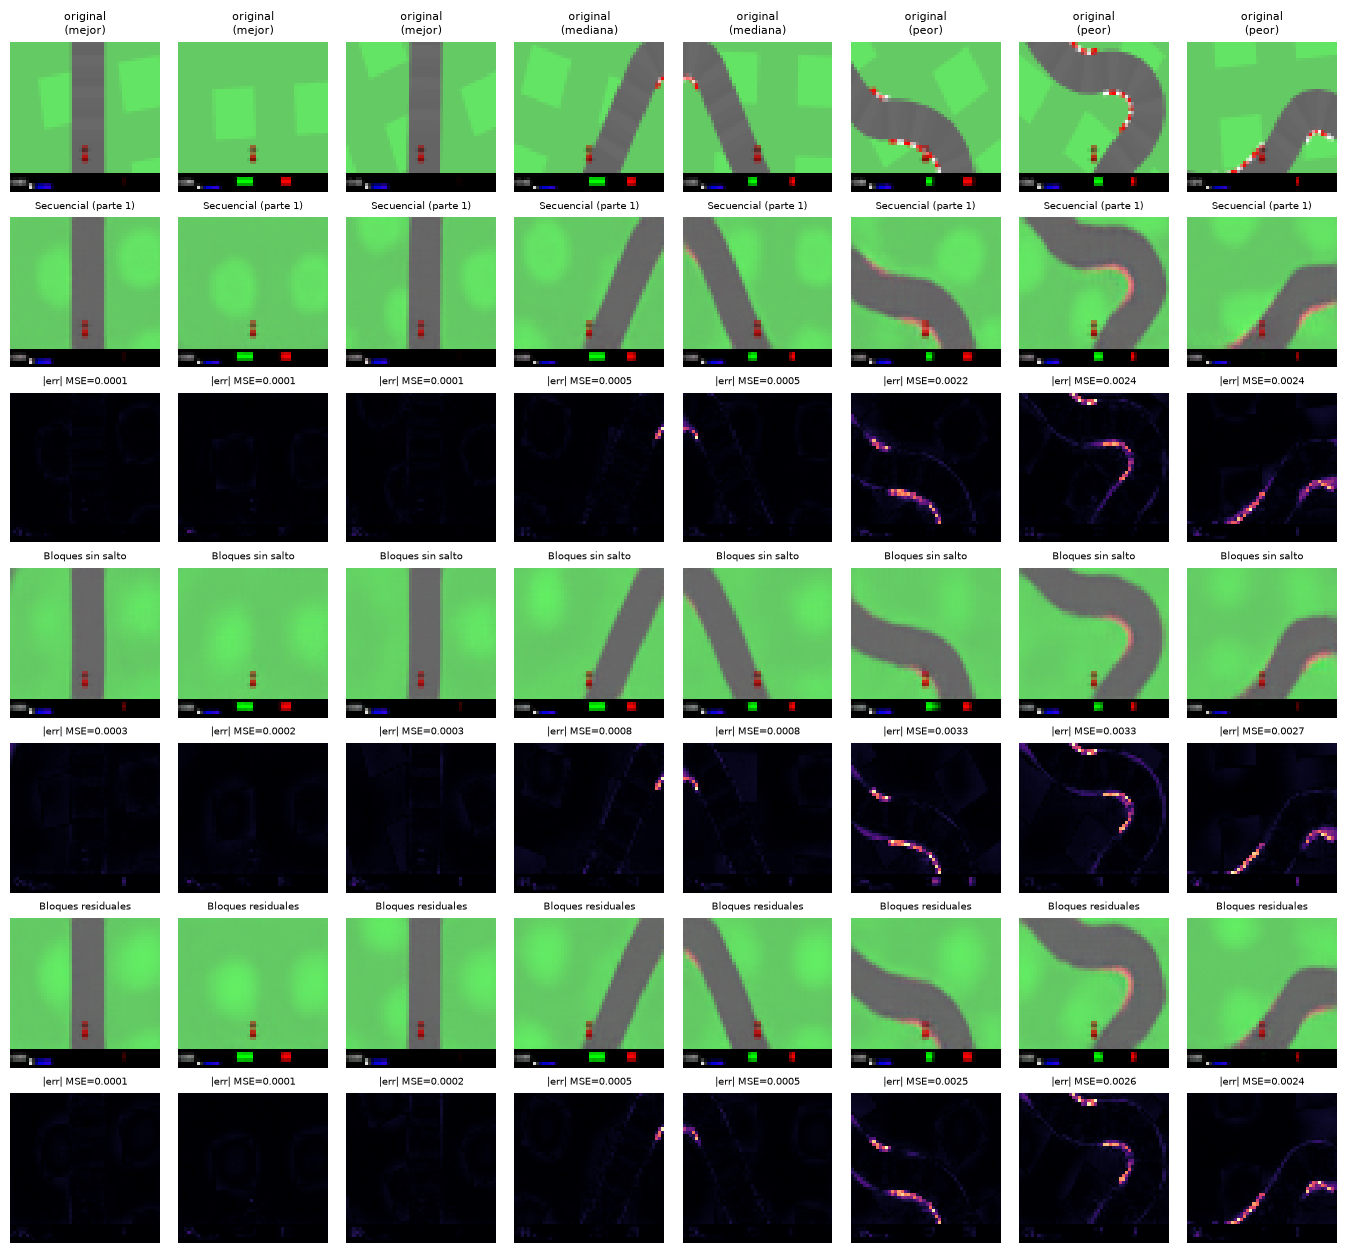

In [12]:
# Selección fija según el error del modelo de la parte 1: 3 mejores, 2 medianas, 3 peores
order = np.argsort(per_img_mse["p1"])
show_idx = list(order[:3]) + list(order[len(order)//2:len(order)//2 + 2]) + list(order[-3:])
labels = ["mejor"] * 3 + ["mediana"] * 2 + ["peor"] * 3

rows_n = 1 + 2 * len(ORDER)
fig, axes = plt.subplots(rows_n, len(show_idx), figsize=(1.7 * len(show_idx), 1.8 * rows_n))
for c, (k, lab) in enumerate(zip(show_idx, labels)):
    axes[0, c].imshow(X_eval[k], interpolation="nearest"); axes[0, c].set_title(f"original\n({lab})", fontsize=8)
    for r, key in enumerate(ORDER):
        err = np.abs(X_eval[k] - rec_eval[key][k]).mean(-1)               # error absoluto medio por píxel
        axes[1 + 2*r, c].imshow(rec_eval[key][k], interpolation="nearest")
        axes[1 + 2*r, c].set_title(LABELS[key], fontsize=7)
        axes[2 + 2*r, c].imshow(err, cmap="magma", vmin=0, vmax=0.5)
        axes[2 + 2*r, c].set_title(f"|err| MSE={per_img_mse[key][k]:.4f}", fontsize=7)
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

### 4.4 Mapa de error medio y error por zona
Error medio por píxel sobre las 512 imágenes, con la misma escala de color. Debajo, el MSE separado en la **zona de juego** (filas 0–41: pista, hierba, coche, bordillos) y la **barra inferior de indicadores** (filas 42–47: velocidad, ABS, dirección y giroscopio), que en la parte 1 fue lo que distinguió a d = 32 de d = 128.

**Qué se observa:**
- El error es bajo en casi toda la imagen. La zona más caliente es la **esquina inferior izquierda** de la barra (indicadores de velocidad/ABS, pequeños y de colores nítidos) y se repite en los tres modelos.
- `seq` tiene además un fondo algo más morado en toda la zona de juego; `res` y `p1` se parecen.
- En los tres, el MSE medio de la zona de juego es mayor que el de la barra: la barra es casi toda negra (fácil) y la zona de juego contiene los bordillos (difíciles).
- `res` frente a `seq`: el MSE baja un ≈ 28 % en la zona de juego (0,00101 → 0,00073) y un ≈ 51 % en la barra (0,00051 → 0,00025). `p1` sigue algo por delante (0,00064 y 0,00021).

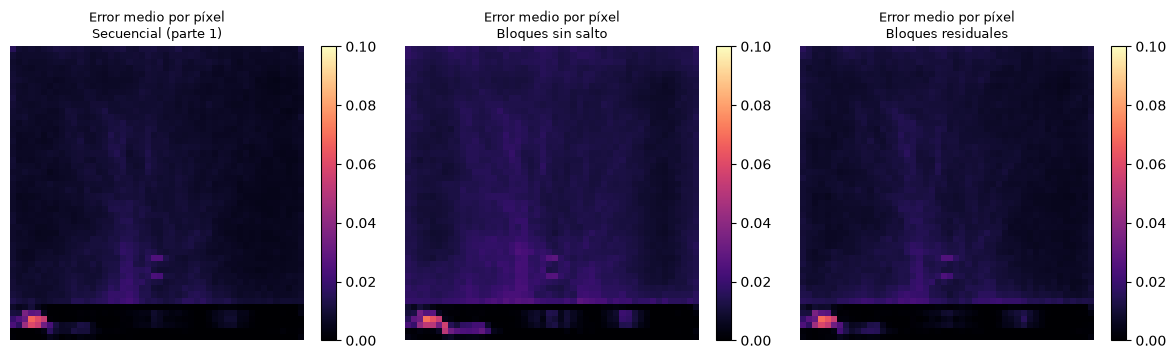

,Secuencial (parte 1),Bloques sin salto,Bloques residuales
MSE zona de juego,0.00064,0.00101,0.00073
MSE barra inferior,0.00021,0.00051,0.00025


In [13]:
# Mapa de error absoluto medio por píxel, misma escala de color en los tres modelos
fig, axes = plt.subplots(1, len(ORDER), figsize=(4 * len(ORDER), 3.5))
for ax, key in zip(axes, ORDER):
    im = ax.imshow(np.abs(X_eval - rec_eval[key]).mean(axis=(0, -1)), cmap="magma", vmin=0, vmax=0.1)
    ax.set_title(f"Error medio por píxel\n{LABELS[key]}", fontsize=9); ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=.046)
plt.tight_layout(); plt.show()

# MSE por zona: zona de juego (filas 0-41) y barra de indicadores (filas 42-47)
BAR_START = 42
zone = pd.DataFrame({LABELS[k]: {
    "MSE zona de juego": ((X_eval[:, :BAR_START] - rec_eval[k][:, :BAR_START]) ** 2).mean(),
    "MSE barra inferior": ((X_eval[:, BAR_START:] - rec_eval[k][:, BAR_START:]) ** 2).mean()} for k in ORDER})
zone.style.format("{:.5f}")

### 4.5 Distribución del error por imagen
El MSE medio puede ocultar diferencias. Se compara el MSE de **cada una de las 512 imágenes** entre `seq` y `res` (mismas ramas): histograma del error por imagen, dispersión imagen a imagen y porcentaje de imágenes en las que el residual mejora.

**Qué se observa:**
- `res` reconstruye mejor el **99,0 %** de las imágenes que `seq`, y la mediana del cociente MSE_res / MSE_seq es **0,671** (≈ −33 %). La mejora no viene de unas pocas imágenes: la nube de puntos queda por debajo de la diagonal en todo el rango.
- El histograma tiene **dos grupos**: imágenes fáciles (rectas, MSE ≈ 2·10⁻⁴) y difíciles (curvas con bordillos, ≈ 10⁻³ o más).
- La mejora del salto es mayor en las fáciles (cociente ≈ 0,5) y menor en las curvas con bordillos (≈ 0,8), que es lo que más cuesta a los tres modelos.

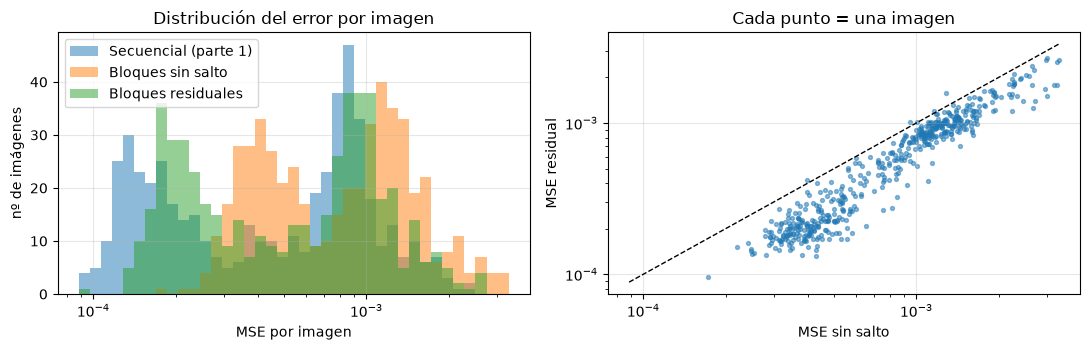

El residual reconstruye mejor el 99.0% de las imágenes (frente al modelo sin salto).
Mediana del cociente MSE_res / MSE_seq: 0.671


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
bins = np.logspace(np.log10(min(v.min() for v in per_img_mse.values())),
                   np.log10(max(v.max() for v in per_img_mse.values())), 40)
for key in ORDER:                                    # histograma del MSE por imagen (eje X logarítmico)
    axes[0].hist(per_img_mse[key], bins=bins, alpha=.5, label=LABELS[key])
axes[0].set_xscale("log"); axes[0].set_xlabel("MSE por imagen"); axes[0].set_ylabel("nº de imágenes")
axes[0].legend(); axes[0].grid(alpha=.3); axes[0].set_title("Distribución del error por imagen")

# Comparación imagen a imagen: puntos por debajo de la diagonal = el residual reconstruye mejor
lo, hi = bins[0], bins[-1]
axes[1].scatter(per_img_mse["seq"], per_img_mse["res"], s=8, alpha=.5)
axes[1].plot([lo, hi], [lo, hi], "k--", lw=1)
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("MSE sin salto"); axes[1].set_ylabel("MSE residual"); axes[1].grid(alpha=.3)
axes[1].set_title("Cada punto = una imagen")
plt.tight_layout(); plt.show()

better = (per_img_mse["res"] < per_img_mse["seq"]).mean() * 100
print(f"El residual reconstruye mejor el {better:.1f}% de las imágenes (frente al modelo sin salto).")
print(f"Mediana del cociente MSE_res / MSE_seq: {np.median(per_img_mse['res'] / per_img_mse['seq']):.3f}")

## 5. Elección del autoencoder para las partes 3 y 4
El criterio es el **menor score en validación** (`val_score`, la métrica del enunciado: SSIM y bordes), mirando después parámetros, tiempo y mejora real frente a las alternativas. El resultado y su justificación están en las conclusiones.

Una vez elegido, el autoencoder se **congela** (`trainable = False` en encoder y decoder) y se **precalculan los latentes de cada partición por separado**:
- `datos/latentes_train.npz`: `(128, 96, d)` · `datos/latentes_valid.npz`: `(32, 96, d)`.
- Tienen la misma forma `(N, T)` que los fotogramas (primeras dos dimensiones), así que en la parte 3 se pueden fraccionar con el mismo código de ventanas.
- El orden de circuitos y de fotogramas es el de `train.npz` y `valid.npz`.

In [ ]:
# Criterio: menor score en validación
ELEGIDO = table["val_score"].astype(float).idxmin()
print("Autoencoder elegido:", ELEGIDO, "→", LABELS[ELEGIDO])
print(table.loc[ELEGIDO, ["params_total", "val_mse", "val_ssim", "val_score"]].to_string())

enc_f, dec_f = enc_dec[ELEGIDO]

# Congelar: sus pesos no se actualizarán en las partes 3 y 4 (si se vuelve a compilar un modelo que los use, hay que
# hacerlo después de este cambio)
enc_f.trainable = False
dec_f.trainable = False
assert len(enc_f.trainable_weights) == 0 and len(dec_f.trainable_weights) == 0
print("Pesos entrenables tras congelar: encoder", len(enc_f.trainable_weights), "| decoder", len(dec_f.trainable_weights))

# Guardar encoder y decoder elegidos en .keras (se cargarán en las partes 3 y 4)
enc_f.save(os.path.join(MODEL_DIR, "encoder_elegido.keras"))
dec_f.save(os.path.join(MODEL_DIR, "decoder_elegido.keras"))

### Latentes por partición
Se codifica cada partición **por separado** con el encoder congelado. `TimeDistributed(encoder)` mantiene la forma de secuencia: `(N, T, 48, 48, 3) → (N, T, d)`. Se verifica que los latentes tienen la forma esperada, que son finitos y que `latentes[n, t]` corresponde a codificar el fotograma `[n, t]` por separado (alineación, lo que necesitará la parte 3). La tolerancia es 10⁻³ porque la GPU no calcula exactamente igual un lote de 8 secuencias que una imagen suelta (diferencias del orden de 10⁻⁴).

In [ ]:
# Envolver el encoder para que acepte secuencias completas: (N, T, 48, 48, 3) -> (N, T, d)
entrada_secuencia = keras.Input((None, 48, 48, 3))
encoder_secuencia = keras.Model(entrada_secuencia,
                                layers.TimeDistributed(enc_f)(entrada_secuencia),
                                name="encoder_secuencias")

# Latentes de cada partición por separado (nunca se mezclan train y valid)
latentes_train = encoder_secuencia.predict(X_train, batch_size=8, verbose=0)   # (128, 96, d)
latentes_val = encoder_secuencia.predict(X_val, batch_size=8, verbose=0)       # (32, 96, d)

# Guardar latentes comprimidos y sus metadatos
np.savez_compressed(os.path.join(DATA_DIR, "latentes_train.npz"), latents=latentes_train)
np.savez_compressed(os.path.join(DATA_DIR, "latentes_valid.npz"), latents=latentes_val)
with open(os.path.join(DATA_DIR, "latentes_meta.json"), "w") as f:
    json.dump({"modelo_elegido": ELEGIDO, "etiqueta": LABELS[ELEGIDO], "latent_dim": LATENT_DIM,
               "train_shape": list(latentes_train.shape), "valid_shape": list(latentes_val.shape),
               "encoder": "modelos/encoder_elegido.keras", "decoder": "modelos/decoder_elegido.keras"},
              f, indent=1)
print("Z_train:", latentes_train.shape, "| Z_val:", latentes_val.shape)

# Comprobaciones: forma, valores finitos y alineación con los fotogramas
assert latentes_train.shape == (X_train.shape[0], X_train.shape[1], LATENT_DIM)
assert latentes_val.shape == (X_val.shape[0], X_val.shape[1], LATENT_DIM)
assert np.isfinite(latentes_train).all() and np.isfinite(latentes_val).all()
latente_individual = enc_f.predict(X_val[3, 17][None], verbose=0)[0]       # codificar el fotograma [3, 17] solo
assert np.allclose(latentes_val[3, 17], latente_individual, atol=1e-3)

print("Latentes verificados")
print(f"Estadísticas de los latentes (train): media={latentes_train.mean():.3f}  desv. típica={latentes_train.std():.3f}")

### Comprobación de los modelos guardados
Se cargan encoder_elegido.keras y decoder_elegido.keras desde disco y se verifica que trabajan con una sola imagen en [0, 1] y que reproducen los resultados en memoria.

In [ ]:
# Los modelos guardados funcionan por separado, con imágenes sueltas, y reproducen el resultado
enc_l = keras.models.load_model(os.path.join(MODEL_DIR, "encoder_elegido.keras"))
dec_l = keras.models.load_model(os.path.join(MODEL_DIR, "decoder_elegido.keras"))
z = enc_l.predict(X_eval[:64], verbose=0)                 # (64, d)
rec = dec_l.predict(z, verbose=0)                         # (64, 48, 48, 3)
assert z.shape == (64, LATENT_DIM) and rec.shape == (64, 48, 48, 3)
assert rec.min() >= 0.0 and rec.max() <= 1.0
assert np.allclose(rec, rec_eval[ELEGIDO][:64], atol=1e-3)
print("encoder_elegido.keras + decoder_elegido.keras ✔  latente", z.shape, "| imagen", rec.shape)
print("Ficheros en modelos/:", sorted(os.listdir(MODEL_DIR)))
print("Ficheros en datos/:", sorted(os.listdir(DATA_DIR)))

## Conclusiones

| | Parámetros | Mejor época | Entreno | MSE val | SSIM val | Score val |
|---|---|---|---|---|---|---|
| Secuencial (parte 1) | 1 610 691 | 54 | 160 s (*) | **0,00058** | **0,947** | **0,0220** |
| Bloques sin salto | 2 155 043 | 60 | 1401 s | 0,00094 | 0,921 | 0,0324 |
| Bloques residuales | 2 155 043 | 60 | 1460 s | 0,00066 | 0,939 | 0,0252 |

(*) Tiempo leído del JSON de la parte 1, no medido en esta ejecución: solo `seq` y `res` son comparables en tiempo.

- **Efecto de la conexión de salto** (comparación controlada `seq` frente a `res`: mismas ramas, mismos parámetros, datos, semilla y 60 épocas): el MSE baja un ≈ 30 %, el SSIM sube de 0,921 a 0,939 y el score baja un ≈ 22 %. La mejora es de **velocidad de convergencia** (1·10⁻³ en la época 26 frente a la 60, sección 4.2) y también de **error final**, y es **general**: `res` reconstruye mejor el 99,0 % de las imágenes (sección 4.5). El motivo es que el salto deja pasar la entrada sin deformar y la rama solo aprende una corrección, así que el gradiente llega mejor a las primeras capas y la red se optimiza antes con el mismo presupuesto.
- **Tiempo y coste:** el salto no añade parámetros y apenas cuesta tiempo: ≈ +4 % de entrenamiento (1401 s → 1460 s) y ≈ +5 % de inferencia (13,6 s → 14,4 s).
- **Qué se reconstruye mejor o peor:** la zona de juego y la barra inferior mejoran con el salto (≈ −28 % y ≈ −51 % de MSE, sección 4.4). En los tres modelos se reconstruyen bien las rectas, la pista, el coche y el indicador de dirección. Se pierden los detalles finos: los bordillos de las curvas salen como una franja rosa difusa (el MSE favorece imágenes «promedio») y el error que queda se concentra en los indicadores de velocidad/ABS de la esquina inferior izquierda (secciones 4.3 y 4.4).
- **Por qué `p1` gana a las dos variantes con bloques:** es la hipótesis más sencilla, no está probada. `p1` es más superficial (5 convoluciones en el encoder frente a 9) y con 60 épocas ya se estabiliza (mejor época 54), mientras que `seq` y `res` siguen mejorando en la última época. Las conexiones residuales ayudan a entrenar redes profundas, pero aquí la red base es poco profunda y el presupuesto es corto; `res` cierra casi toda la distancia que `seq` pierde frente a `p1` (de +62 % a +14 % de MSE), pero no la cierra del todo.
- **Limitaciones:** una sola semilla y un único tamaño latente (d = 128); una diferencia pequeña puede deberse a la inicialización y no a la arquitectura. La comparación `res`–`seq` es controlada; la de `p1` con ambos no lo es (distinta profundidad y número de parámetros). No sabemos si `res` superaría a `p1` con más épocas, porque su curva aún bajaba. Además, los valores de `p1` recalculados aquí difieren algo de los de la parte 1 (sección 4), sin cambiar el orden.
- **Elección final:** **`p1` (autoencoder secuencial de la parte 1, d = 128)**. Criterio: menor score en validación (0,0220 frente a 0,0252 de `res` y 0,0324 de `seq`). Es también el mejor en MSE y SSIM, en las 512 imágenes fijas y en ambas zonas (juego y barra), así que no depende de una sola métrica. Es además el más pequeño (1,61 M frente a 2,16 M de parámetros) y el más rápido en inferencia, y su encoder tiene capas convolucionales a tres profundidades (24×24, 12×12 y 6×6) para la pérdida perceptual de las partes 3 y 4. El autoencoder elegido es el límite inferior del error que podrán alcanzar los predictores de las partes 3 y 4, porque sus imágenes pasan por este mismo decoder. `res` queda como segunda opción: es mejor que `seq` y no necesita más parámetros.
- **Latentes:** `datos/latentes_train.npz` y `datos/latentes_valid.npz` con forma `(N, T, d)` = `(128, 96, 128)` y `(32, 96, 128)`, listos para fraccionar en ventanas en la parte 3. El encoder y el decoder elegidos están en `modelos/encoder_elegido.keras` y `modelos/decoder_elegido.keras`.

## Declaración de ayuda externa e IA

Se utilizó **Claude (Anthropic)** como asistente durante el desarrollo de esta parte. En concreto, se empleó para generar la estructura base del código (bloques convolucionales, autoencoders con y sin salto, evaluación), para simplificar el notebook (eliminar comprobaciones repetidas y la importación de la parte 1) y para redactar los textos explicativos y los comentarios de los resultados a partir de las salidas.
El grupo revisó todo el código, lo ejecutó, decidió qué cambios incorporar y qué configuración usar en la entrega, interpretando los resultados obtenidos. Las conclusiones finales y el análisis se validaron por el grupo a partir de las salidas del notebook.

Los ficheros proporcionados por el profesor (`dataset.py`, `carracing48.py`, `metric.py`) se usaron sin modificaciones.